In [2]:
from io import StringIO
import glob
import os
from os import listdir, path, makedirs
import re
import pandas as pd
import subprocess
import argparse
from Bio.Seq import Seq
from Bio import SeqIO
from Bio.SeqRecord import SeqRecord

In [46]:
import pandas as pd
import Levenshtein
# Function to check if seq_1 is a near-substring (tolerating one error) of any seq_2
def is_near_substring(seq_1):
    for seq_2 in df_2['original_sequence']:
        for i in range(len(seq_2) - len(seq_1) + 1):  # Slide seq_1 over seq_2
            sub_seq = seq_2[i:i+len(seq_1)]  # Extract substring of same length
            if Levenshtein.distance(seq_1, sub_seq) <= 1:  # Allow one error
                return seq_2  # Match found
    return ''  # No match found

df_1 = pd.read_csv("csv_data/eq_not_map_test1_frequency.csv", sep="\t")
df_2 = pd.read_csv("data/whole_paper_sequences.csv", sep="\t")

df_1['original_sequence'] = df_1['sequence'].apply(is_near_substring)



In [47]:
real_count= df_1.loc[df_1['original_sequence'] != '', 'count'].sum()
count = df_1['count'].sum()
# count = len(df_1)
print("mapping percentage",round((real_count /count) * 100,2))
print(df_1)

mapping percentage 70.23
                       sequence  count        original_sequence
0         AGACATGTGCTCTGCTCCTAA  19851    AGACATGTGCTCTGCTCCTAG
1        TAACTGGTTGAACAACTGAACT  16297   TAACTGGTTGAACAACTGAACC
2        TCAGTGCACTACAGAACTTTGC  13911   TCAGTGCACTACAGAACTTTGT
3       ATGTATGGCTGGCGTACGTCGTA  12889  ATGTATGGCTGGCGTACGTCGTG
4        TGGACGGAGAACTGATAAGGGC  11627   TGGACGGAGAACTGATAAGGGT
...                         ...    ...                      ...
225715    AAAGTGGTAACTTTTGAGTGG      1                         
225716    CTAGATGGCTCCTCCATGTCT      1    CTGGATGGCTCCTCCATGTCT
225717   CAGCTCGGCTGTCTTAACCTCT      1                         
225718   AGCGGTCTGTTCAGGTGGACGG      1                         
225719   GTCACAACCATGGGGTCGTAGA      1                         

[225720 rows x 3 columns]


In [48]:
df_1=df_1[df_1['original_sequence'] != '']
print(df_1)
df_1 = df_1[['original_sequence','count']]
df_1new = df_1.groupby('original_sequence', as_index=False)['count'].sum()
print(df_1new)


                       sequence  count        original_sequence
0         AGACATGTGCTCTGCTCCTAA  19851    AGACATGTGCTCTGCTCCTAG
1        TAACTGGTTGAACAACTGAACT  16297   TAACTGGTTGAACAACTGAACC
2        TCAGTGCACTACAGAACTTTGC  13911   TCAGTGCACTACAGAACTTTGT
3       ATGTATGGCTGGCGTACGTCGTA  12889  ATGTATGGCTGGCGTACGTCGTG
4        TGGACGGAGAACTGATAAGGGC  11627   TGGACGGAGAACTGATAAGGGT
...                         ...    ...                      ...
225699    TCGGATCCGTCTGACCTTGGC      1   TCGGATCCGTCTGAGCTTGGCT
225707        GAGGTAGGAGGTTGTAC      1   TGAGGTAGGAGGTTGTATAGTT
225710     AAAGTGCTGACAGTGTAGAT      1    TAAAGTGCTGACAGTGCAGAT
225713      AGTGTAGTTAGCTGATTAC      1  AGGCAGTGTAGTTAGCTGATTGC
225716    CTAGATGGCTCCTCCATGTCT      1    CTGGATGGCTCCTCCATGTCT

[51100 rows x 3 columns]
           original_sequence  count
0      AAAACCTTCAGAAGGAAAGAA      1
1      AAAACGGTGAGATTTTGTTTT     16
2     AAAAGCTGGGTTGAGAGGGCGA    460
3     AAAAGTAATTGCGGTTTTTGCC      4
4    AAAAGTGCTTACAGTGCAGGT

In [49]:
df_3 = pd.read_csv("csv_data/eq_map_test1_new.csv", sep="\t")
df_3 = df_3[df_3['original_sequence'].notna()]
# print(df_3)
# df_1new = df_1[['original_sequence','count']]
#print(df_1new)

merged_df = df_1new.merge(df_3, on='original_sequence', how='outer', suffixes=('_df1', '_df2'))
print(merged_df)
merged_df['count'] = merged_df['count_df1'].fillna(0) + merged_df['count_df2'].fillna(0)
print(merged_df)

merged_df = merged_df[['original_sequence', 'count']]
print(merged_df)
final_df = df_2.merge(merged_df, on='original_sequence', how='left')
print(final_df)
merged_df.to_csv('eq_map_test1_tolerance2_frequency.csv', sep='\t', index=False)

                                      original_sequence  count_df1  count_df2
0                                 AAAACCTTCAGAAGGAAAGAA        1.0        1.0
1                                 AAAACGGTGAGATTTTGTTTT       16.0       22.0
2                                AAAAGCTGGGTTGAGAGGGCGA      460.0      885.0
3                                AAAAGTAATTGCGGTTTTTGCC        4.0        1.0
4                               AAAAGTGCTTACAGTGCAGGTAG        8.0       20.0
...                                                 ...        ...        ...
1047                            GAACGCCTGTTCTTGCCAGGTGG        NaN        1.0
1048                             TTCTCCAAAAGGGAGCACTTTC        NaN        1.0
1049                             AAGCCCTTACCCCAAAAAGCAT        NaN        1.0
1050                                AGTTTTCCCTTCAAGTCAA        NaN        1.0
1051  GCCACGCCCCCATCCTGTGCCTATAAAAACTCCCGAGACCCTAGCG...        NaN        1.0

[1052 rows x 3 columns]
                                      o

above code end

In [4]:
csv_file = "csv_data/eq_map_test1_new.csv"  
df = pd.read_csv(csv_file,sep="\t")
csv_whole_file = "data/whole_paper_sequences.csv"  
df_w = pd.read_csv(csv_whole_file,sep="\t")
# print(df['sequence'])
merged_df = df_w.merge(df, on='original_sequence', how='left')
merged_df.fillna(0, inplace=True)
print(merged_df)

                                      original_sequence   count
0                               TACATAACCATGGAGTTGGCTGT  8227.0
1                                TAACCTGATCAGCCCCGGAGTT  1560.0
2                                 ACGCACACCAGGCTGACTGCC    33.0
3                              TCAGACAGTTTGGTGCGCTAGTTG    11.0
4                                TCCTGTGGTGTTTGGTGTGGTT  3244.0
...                                                 ...     ...
1147                     CCGCCTTTAAGAACTGTAACACTCACTGCG    30.0
1148      ACTCCGAACACATCTGAACATCAGAAGCAACAAACTCCGGACACG    99.0
1149  GCTGTAACACTCACCGCGAAGGTCTGCAGCTTCACTCCTGAGCCAG...    53.0
1150  ACCGCGAAGGTCCGCAGCTTCACTCCTGAAGCCAGCGAGACCACGA...     5.0
1151  AGAGAATAAAAGCAGGCTGCCCGAGCCAGCAGTGGCAACCTGATGG...    28.0

[1152 rows x 2 columns]


map 1152 sequences code:

In [6]:
record_dict = SeqIO.to_dict(SeqIO.parse("data/final_test4.fasta", "fasta"))
sequence_list = [str(record.seq) for record in record_dict.values() if 16 <= len(record.seq) <= 25]
df = pd.DataFrame(sequence_list, columns=["sequence"])
dfa = df["sequence"]
num_lines = len(dfa)
print(f"The number of sequences is: {num_lines}")
print("original mirdeep2 sequences:\t", dfa)
num_lines = len(dfa)
print(f"The number of sequences is: {num_lines}")

The number of sequences is: 13111264
original mirdeep2 sequences:	 0             CAGTCATGCCGCTTGCCTACG
1              CTTTTTGCGGTCTGGGCTTG
2            CAACAAATCACAGTCTGCCATA
3           TGTAACAGCAAACTCCATGTGGA
4            AACTGTAGTCCGGGTCGATCTG
                     ...           
13111259     TCCTGTACTGAGCTGCCCGAGA
13111260    TGCAACGAACCTGAGCCACTGAG
13111261     TGGTTTACCGTCCCACATACAT
13111262     AGGCAAGATGCTGGCATAGCTG
13111263      AGGCCTGGCCCAGACCTCAGC
Name: sequence, Length: 13111264, dtype: object
The number of sequences is: 13111264


In [7]:
def map_to_seq_b(seq_a,df_csv):
    for seq_b in df_csv['sequence']:
        if seq_a in seq_b:
            return seq_b  
    return ''  

In [9]:
df_csv = pd.read_csv("data/1152_paper_sequences.csv", sep="\t")
df_csv.columns =["sequence","unkown"]
# print(df_csv)
# df_subset_csv = dfa['sequence']
# print(df_subset_csv)

# df.loc[:, 'is_substring'] = dfa.apply(
#     lambda seq_a: any(seq_a in seq_b for seq_b in df_subset_csv)
# )
# Function to map seq_a to the first matching seq_b or return an empty string



df['mapped_seq_b'] = dfa.apply(map_to_seq_b, args=(df_csv,))

mapped_seq_b_counts = df['mapped_seq_b'].value_counts()


mapped_seq_b_counts_df = mapped_seq_b_counts.reset_index()
mapped_seq_b_counts_df.columns = ['original_sequence', 'count']

# df['is_substring'] = df['mapped_seq_b'] != ''


# result = df[df['is_substring']]


mapped_seq_b_counts_df.loc[mapped_seq_b_counts_df['original_sequence'] == '', 'count'] = 0
real_count = mapped_seq_b_counts_df['count'].sum()
print("real count",real_count)
print("df_csv length", len(dfa))
count = len(dfa)
print("mapping percentage",round((real_count /count) * 100,2))
mapped_seq_b_counts_df.to_csv('eq_map_test4_new.csv', sep='\t', index=False)

real count 10220056
df_csv length 13111264
mapping percentage 77.95


In [8]:
df = pd.read_csv("data/1152_paper_sequences.csv",sep="\t")
print(df)
df = df[(df['Sequence'].str.len() < 16) | (df['Sequence'].str.len() > 25)]
newdf =df['Sequence']
# df = pd.DataFrame(sequence_list)
newdf.to_csv('data/longer_paper_sequences.csv', sep='\t', index=False)

                                               Sequence  Unnamed: 1
0                               TACATAACCATGGAGTTGGCTGT         NaN
1                                TAACCTGATCAGCCCCGGAGTT         NaN
2                                 ACGCACACCAGGCTGACTGCC         NaN
3                              TCAGACAGTTTGGTGCGCTAGTTG         NaN
4                                TCCTGTGGTGTTTGGTGTGGTT         NaN
...                                                 ...         ...
1147                     CCGCCTTTAAGAACTGTAACACTCACTGCG         NaN
1148      ACTCCGAACACATCTGAACATCAGAAGCAACAAACTCCGGACACG         NaN
1149  GCTGTAACACTCACCGCGAAGGTCTGCAGCTTCACTCCTGAGCCAG...         NaN
1150  ACCGCGAAGGTCCGCAGCTTCACTCCTGAAGCCAGCGAGACCACGA...         NaN
1151  AGAGAATAAAAGCAGGCTGCCCGAGCCAGCAGTGGCAACCTGATGG...         NaN

[1152 rows x 2 columns]


not map 1152 sequences code:

In [ ]:
record_dict = SeqIO.to_dict(SeqIO.parse("data/final_test2.fasta", "fasta"))
sequence_list = [str(record.seq) for record in record_dict.values() if 16 <= len(record.seq) <= 25]
    #  df = pd.read_csv("data/1152_paper_sequences.csv",sep="\t")
    # print(df)
    # df = df[(df['Sequence'].str.len() < 16) | (df['Sequence'].str.len() >= 25)]
    # newdf =df['Sequence']
    # # df = pd.DataFrame(sequence_list)
    # newdf.to_csv('data/longer_paper_sequences.csv', sep='\t', index=False)
df = pd.DataFrame(sequence_list, columns=["sequence"])
num_lines = len(df)
# dfa = df["sequence"]
# print(len(dfa))
# print(dfa)
print(f"The number of sequences is: {num_lines}")
print("original mirdeep2 sequences:\t", df)
# df.sort_values(by="sequence", inplace=True)
# df = df.copy()
# df.drop_duplicates(subset=["sequence"], inplace=True)
# # df.drop_duplicates(subset=["sequence"], inplace=True)
# # df = df[~df['sequence'].str.contains("N")]
# #df.reset_index(drop=True, inplace=True):q
# print("mirdeep2 sequences after filtering redundants:\t", df)
num_lines = len(df)
print(f"The number of sequences is: {num_lines}")

The number of sequences is: 9040011
original mirdeep2 sequences:	                           sequence
0          TGCACCATGGTTGTCTGAGCATG
1        TTGGAGGATGAAAGTACGGAGTGAT
2           CTTGGAGTAGGTCATTGGGTGG
3             TAGACTGAAGCTCCTTGAGG
4           TGCAACGAACCTGAGCCACTGA
...                            ...
9040006     GGGGCTGGGGCCGGGACAGAGC
9040007    TACCCTGTAGAACCGAATTTGTG
9040008     TGTGACTGGTTGACCAGAGGGG
9040009       GAATTGATCAGGACATAGGG
9040010      TGGAAGGACGGGAAGTGGAAG

[9040011 rows x 1 columns]
The number of sequences is: 9040011


In [ ]:
df_csv = pd.read_csv("data/1152_paper_sequences.csv", sep="\t")
df_csv.columns =["sequence","unkown"]
print(df_csv)
df_subset_csv = df_csv['sequence']
print(df_subset_csv)

                                               sequence  unkown
0                               TACATAACCATGGAGTTGGCTGT     NaN
1                                TAACCTGATCAGCCCCGGAGTT     NaN
2                                 ACGCACACCAGGCTGACTGCC     NaN
3                              TCAGACAGTTTGGTGCGCTAGTTG     NaN
4                                TCCTGTGGTGTTTGGTGTGGTT     NaN
...                                                 ...     ...
1147                     CCGCCTTTAAGAACTGTAACACTCACTGCG     NaN
1148      ACTCCGAACACATCTGAACATCAGAAGCAACAAACTCCGGACACG     NaN
1149  GCTGTAACACTCACCGCGAAGGTCTGCAGCTTCACTCCTGAGCCAG...     NaN
1150  ACCGCGAAGGTCCGCAGCTTCACTCCTGAAGCCAGCGAGACCACGA...     NaN
1151  AGAGAATAAAAGCAGGCTGCCCGAGCCAGCAGTGGCAACCTGATGG...     NaN

[1152 rows x 2 columns]
0                                 TACATAACCATGGAGTTGGCTGT
1                                  TAACCTGATCAGCCCCGGAGTT
2                                   ACGCACACCAGGCTGACTGCC
3                                

In [ ]:
dfa = df["sequence"]
df.loc[:, 'is_substring'] = dfa.apply(
    lambda seq_a: any(seq_a in seq_b for seq_b in df_subset_csv)
)

# Filter to find only the sequences in df_a that are substrings in df_b
# result = df[df['is_substring']]
# print(round(len(result) /len(df) * 100,2))
# result.to_csv('eq_map_test1.csv', sep='\t', index=False)
# Display the result
# print(result)

In [ ]:
not_substring_result = df[~df['is_substring']]
print(not_substring_result)
# not_substring_result = not_substring_result.copy()
# not_substring_result.drop_duplicates(subset=["sequence"], inplace=True)
# print(not_substring_result)
not_substring_result.to_csv('eq_not_map_test2.csv', sep='\t', index=False)



                        sequence  is_substring
0        TCCGGGACTGAGATCTGTGCACC         False
4         TATGCATTGTATTTTTAGGACC         False
6          TACCCTGTAGATCCGAATTTT         False
7        GTGTGTGGAAATGCTTCTGGCTA         False
9          AGACATGTGCTCTGCTCCTAA         False
...                          ...           ...
8350980    CTTTTTGCGGTCTGCTCTTGC         False
8350996      CACTGAGTCCTATCTGCGT         False
8351030    GTGTCTTTTGCTATGAAGTCA         False
8351046   CAAAGAGCTCTAGTACAGGTAG         False
8351069   ATCTGAACGAAAGAAGCACTTA         False

[225720 rows x 2 columns]
                        sequence  is_substring
0        TCCGGGACTGAGATCTGTGCACC         False
4         TATGCATTGTATTTTTAGGACC         False
6          TACCCTGTAGATCCGAATTTT         False
7        GTGTGTGGAAATGCTTCTGGCTA         False
9          AGACATGTGCTCTGCTCCTAA         False
...                          ...           ...
8350980    CTTTTTGCGGTCTGCTCTTGC         False
8350996      CACTGAGTCCTATCTGCGT 

In [ ]:
dfa = df["sequence"]
df_csv['is_substring'] = df_csv['sequence'].apply(
    lambda seq_b: any(seq_b in seq_a for seq_a in dfa)
)


result = df_csv[df_csv['is_substring']]

print(result['sequence'])

                      sequence  unkown  is_substring
0      TACATAACCATGGAGTTGGCTGT     NaN          True
1       TAACCTGATCAGCCCCGGAGTT     NaN          True
2        ACGCACACCAGGCTGACTGCC     NaN          True
3     TCAGACAGTTTGGTGCGCTAGTTG     NaN          True
4       TCCTGTGGTGTTTGGTGTGGTT     NaN          True
...                        ...     ...           ...
991      TAGACCATTTGTGAGAAGGGA     NaN          True
1029           CTGGCCTGCAGCTGG     NaN          True
1059           GCGGCAAAAAAAAAA     NaN          True
1073     TCGCTTGGTGCAGATCGGGAC     NaN          True
1109           AAGGTACTCTACAGT     NaN          True

[921 rows x 3 columns]


new update july 24, 2025

In [6]:
import pandas as pd
df = pd.read_csv("data/shorter_paper_sequences.csv",sep="\t")
print(df)

lengths = df['Sequence'].astype(str).apply(len)
newdf = df[(lengths >= 16) & (lengths <= 25)]
# print(len(newdf))
print(lengths)
print("All lengths:\n", lengths.tolist())
print("Min length:", lengths.min())
print("Max length:", lengths.max())


# newdf =df['Sequence']
print(len(newdf))

                     Sequence
0     TACATAACCATGGAGTTGGCTGT
1      TAACCTGATCAGCCCCGGAGTT
2       ACGCACACCAGGCTGACTGCC
3    TCAGACAGTTTGGTGCGCTAGTTG
4      TCCTGTGGTGTTTGGTGTGGTT
..                        ...
976   ACATATGGCTGGCGTACGTCCAT
977      TGACAGAAGAGAGTGAGCAC
978     TAGACCATTTGTGAGAAGGGA
979     AGAATCTTGATGATGCTGCAT
980     TCGCTTGGTGCAGATCGGGAC

[981 rows x 1 columns]
0      23
1      22
2      21
3      24
4      22
       ..
976    23
977    20
978    21
979    21
980    21
Name: Sequence, Length: 981, dtype: int64
All lengths:
 [23, 22, 21, 24, 22, 22, 22, 23, 22, 22, 22, 22, 22, 24, 24, 23, 22, 22, 22, 21, 23, 22, 21, 24, 22, 22, 21, 22, 24, 22, 22, 22, 23, 22, 23, 22, 21, 20, 22, 22, 20, 21, 21, 23, 22, 20, 22, 22, 21, 22, 20, 24, 21, 20, 23, 22, 22, 22, 22, 22, 23, 21, 22, 22, 22, 22, 22, 21, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 21, 22, 22, 22, 22, 22, 21, 21, 23, 23, 23, 23, 23, 23, 21, 23, 23, 23, 22, 20, 24, 22, 22, 21, 22, 21, 2

In [1]:
import pandas as pd
df = pd.read_csv("data/1152_paper_sequences.csv",sep="\t")
print(df)

lengths = df['Sequence'].astype(str).apply(len)
newdf = df[(lengths >= 16) & (lengths <= 25)]
# print(len(newdf))
print(lengths)
print("All lengths:\n", lengths.tolist())
print("Min length:", lengths.min())
print("Max length:", lengths.max())


# newdf =df['Sequence']
print(len(newdf))

                                               Sequence  Unnamed: 1
0                               TACATAACCATGGAGTTGGCTGT         NaN
1                                TAACCTGATCAGCCCCGGAGTT         NaN
2                                 ACGCACACCAGGCTGACTGCC         NaN
3                              TCAGACAGTTTGGTGCGCTAGTTG         NaN
4                                TCCTGTGGTGTTTGGTGTGGTT         NaN
...                                                 ...         ...
1147                     CCGCCTTTAAGAACTGTAACACTCACTGCG         NaN
1148      ACTCCGAACACATCTGAACATCAGAAGCAACAAACTCCGGACACG         NaN
1149  GCTGTAACACTCACCGCGAAGGTCTGCAGCTTCACTCCTGAGCCAG...         NaN
1150  ACCGCGAAGGTCCGCAGCTTCACTCCTGAAGCCAGCGAGACCACGA...         NaN
1151  AGAGAATAAAAGCAGGCTGCCCGAGCCAGCAGTGGCAACCTGATGG...         NaN

[1152 rows x 2 columns]
0       23
1       22
2       21
3       24
4       22
        ..
1147    30
1148    45
1149    60
1150    75
1151    90
Name: Sequence, Length: 1152, dtype: i

fasta file compare with known 977 sequences (step1: exact match + umi count figure)

In [2]:
from io import StringIO
import glob
import os
from os import listdir, path, makedirs
import re
import pandas as pd
import subprocess
import argparse
from Bio.Seq import Seq
from Bio import SeqIO
from Bio.SeqRecord import SeqRecord
import pandas as pd
import Levenshtein
import matplotlib.pyplot as plt

dfa                   sequence  count
0  ATCCCTTGCAGGGGCTGTTGGGT      3
1   CGTCAACACTTGCTGGTTTCCT      3
2    ATTGCACGGTATCCATCTGTA      3
3   CAACCTGGAGGACTCCATGCTG      2
4  ATATATGGCTGGCGTACGTAGTG      2
Missing sequences:
118
match sequences:
96
total sequences:
214
Missing sequences:
881
match sequences:
96
total sequences:
977


<Figure size 1000x500 with 0 Axes>

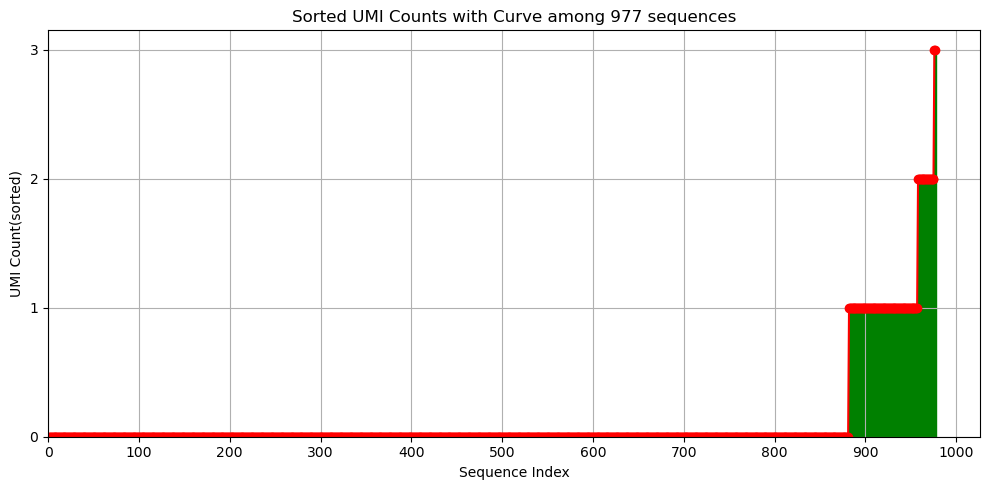

In [27]:
    seq_dict = SeqIO.to_dict(SeqIO.parse("data/output_top500.fasta", "fasta"))
    sequence_list = [str(record.seq) for record in seq_dict.values() if 16 <= len(record.seq) <= 25]
    df = pd.DataFrame(sequence_list, columns=["sequence"])
    # dfb = df["sequence"]
    dfa = df["sequence"].value_counts().reset_index()
    dfa.columns = ["sequence", "count"]
    print("dfa",dfa.head(5))

    df_csv = pd.read_csv("data/shorter_paper_sequences.csv", sep="\t")
    df_csv.columns =["sequence"]


    dfa['found_in_df2'] = dfa['sequence'].isin(df_csv['sequence'])
    missing_seqs_fasta = dfa.loc[~dfa['found_in_df2'], 'sequence']
    print("Missing sequences:")
    print(len(missing_seqs_fasta))
    match_seqs_fasta = dfa.loc[dfa['found_in_df2'], 'sequence']
    print("match sequences:")
    print(len(match_seqs_fasta))
    print("total sequences:")
    print(len(dfa))

    
    df_csv['found_in_df2'] = df_csv['sequence'].isin(dfa['sequence'])
    missing_seqs = df_csv.loc[~df_csv['found_in_df2'], 'sequence']
    print("Missing sequences:")
    print(len(missing_seqs))
    match_seqs = df_csv.loc[df_csv['found_in_df2'], 'sequence']
    print("match sequences:")
    print(len(match_seqs))
    print("total sequences:")
    print(len(df_csv))

    umi_dict = SeqIO.to_dict(SeqIO.parse("data/output_top500_umi.fasta", "fasta"))

    # Create list of rows: (seq_id, main_sequence, umi_sequence)
    data = []
    for seq_id in seq_dict:
        if seq_id in umi_dict:
            seq = str(seq_dict[seq_id].seq)
            umi = str(umi_dict[seq_id].seq)
            data.append((seq, umi))

  
    df = pd.DataFrame(data, columns=["sequence", "umi"])
    df = df[df['sequence'].str.len().between(16, 25)]
    df_dedup = df.groupby(["sequence", "umi"]).size().reset_index(name="count")
    merged = pd.merge(df_csv, df_dedup, how='left', on='sequence')
    count_df = merged.groupby('sequence')['umi'].count().reset_index(name='umi_count')
    count_df_sorted = count_df.sort_values(by='umi_count')
    # print(count_df_sorted)
    count_df_sorted.to_csv("seq_and_umi_count_4N_A.csv", index=False)

    plt.figure(figsize=(10, 5))
    x = range(1, len(count_df_sorted) + 1)
    y = count_df_sorted["umi_count"]
    plt.figure(figsize=(10, 5))
    plt.bar(x, y, color='green', edgecolor='green', label='Bar')
    plt.plot(x, y, marker='o', linestyle='-', color='red')
    plt.xlabel('Sequence Index')
    plt.ylabel('UMI Count(sorted)')
    plt.title('Sorted UMI Counts with Curve among 977 sequences')
    plt.grid(True)
    plt.xlim(left=0)
    plt.xticks(ticks=range(0, len(count_df_sorted)+100, 100))
    plt.yticks(ticks=range(0, max(count_df_sorted["umi_count"])+1, 1))
    plt.tight_layout()
    plt.savefig("umi_count_histogram_4N_A_977.png", dpi=300)  
  

<Figure size 1000x500 with 0 Axes>

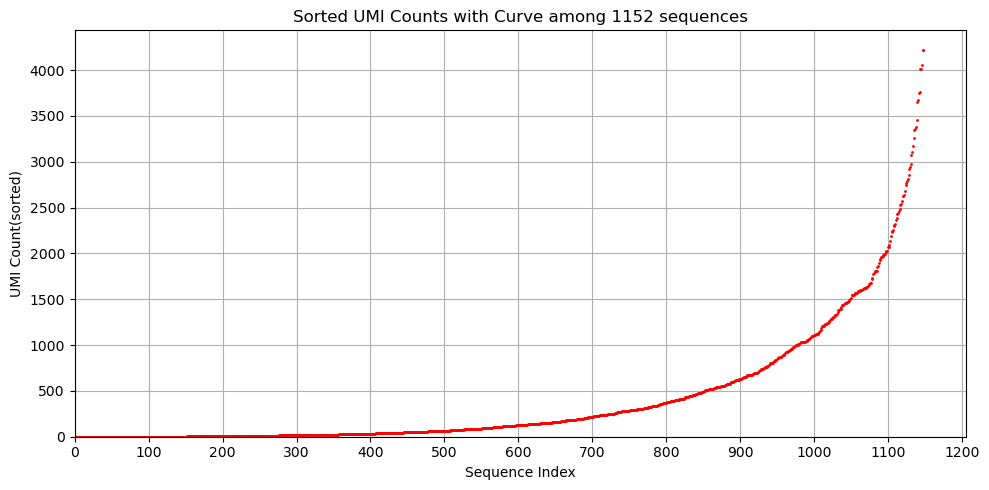

In [3]:
    count_df_sorted = pd.read_csv("seq_and_umi_count_4N_Nextflex_1152.csv")
  
    plt.figure(figsize=(10, 5))
    x = range(1, len(count_df_sorted) + 1)
    y = count_df_sorted["umi_count"]
    plt.figure(figsize=(10, 5))
    # plt.bar(x, y, color='green', edgecolor='green', width=0.1,label='Bar')
    plt.plot(x, y, marker='o', linestyle='None', color='red',markersize=1)
    plt.xlabel('Sequence Index')
    plt.ylabel('UMI Count(sorted)')
    plt.title('Sorted UMI Counts with Curve among 1152 sequences')
    plt.grid(True)
    plt.xlim(left=0)
    plt.ylim(bottom=0)
    plt.xticks(ticks=range(0, len(count_df_sorted)+100, 100))
    plt.savefig("umi_count_histogram_4N_Nextflex_1152.png", dpi=300)
    plt.tight_layout()

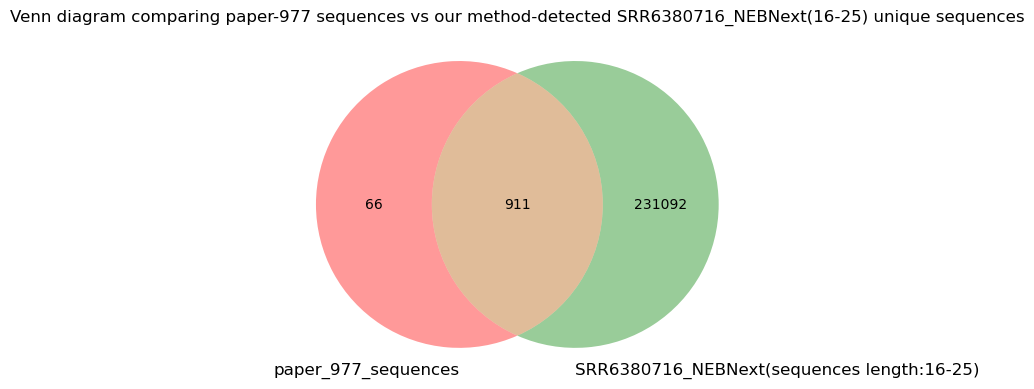

In [3]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted

plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("66","231092","911")
, set_labels=('paper_977_sequences', 'SRR6380716_NEBNext(sequences length:16-25)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")

plt.title("Venn diagram comparing paper-977 sequences vs our method-detected SRR6380716_NEBNext(16-25) unique sequences")
plt.show()

In [15]:
import pandas as pd

df_csv = pd.DataFrame({
    'sequence': ['ACGT','TTGC','GGCA','ACGT']
})

df_dedup = pd.DataFrame({
    'sequence': ['ACGT', 'TTGC', 'ACGT', 'GGCA', 'ACGT','TTGC'],
    'umi': ['umi1', 'umi2', 'umi3', 'umi4', 'umi5','umi6']
})

merged = pd.merge(df_csv, df_dedup, how='left', on='sequence')
print(merged)


  sequence   umi
0     ACGT  umi1
1     ACGT  umi3
2     ACGT  umi5
3     TTGC  umi2
4     TTGC  umi6
5     GGCA  umi4
6     ACGT  umi1
7     ACGT  umi3
8     ACGT  umi5


In [4]:
df_csv = pd.read_csv("data/seq_and_seq_count_cleantag_1152.csv", sep="\t")
df_csv.columns =["sequence","count"]
print(df_csv)
# df_unique = df_csv.drop_duplicates()
# print(df_unique)

FileNotFoundError: [Errno 2] No such file or directory: 'data/seq_and_seq_count_cleantag_1152.csv'

In [14]:
df_csv = pd.read_csv("data/1152_paper_sequences.csv", sep="\t")
df_csv.columns =["sequence","unkown"]
df_csv = df_csv.drop(columns=["unkown"])
print(df_csv)
df_unique = df_csv.drop_duplicates()
print(df_unique)


                                               sequence
0                               TACATAACCATGGAGTTGGCTGT
1                                TAACCTGATCAGCCCCGGAGTT
2                                 ACGCACACCAGGCTGACTGCC
3                              TCAGACAGTTTGGTGCGCTAGTTG
4                                TCCTGTGGTGTTTGGTGTGGTT
...                                                 ...
1147                     CCGCCTTTAAGAACTGTAACACTCACTGCG
1148      ACTCCGAACACATCTGAACATCAGAAGCAACAAACTCCGGACACG
1149  GCTGTAACACTCACCGCGAAGGTCTGCAGCTTCACTCCTGAGCCAG...
1150  ACCGCGAAGGTCCGCAGCTTCACTCCTGAAGCCAGCGAGACCACGA...
1151  AGAGAATAAAAGCAGGCTGCCCGAGCCAGCAGTGGCAACCTGATGG...

[1152 rows x 1 columns]
                                               sequence
0                               TACATAACCATGGAGTTGGCTGT
1                                TAACCTGATCAGCCCCGGAGTT
2                                 ACGCACACCAGGCTGACTGCC
3                              TCAGACAGTTTGGTGCGCTAGTTG
4                      

In [3]:
import pandas as pd

import pandas as pd

data = [
    ["480 / 500", "96.0%", "490 / 500", "98.0%"],
    ["450 / 500", "90.0%", "470 / 500", "94.0%"]
]

columns = pd.MultiIndex.from_tuples([
    ("Substring", "Match Sequences / Total"),
    ("Substring", "Mapping Rate (%)"),
    ("Substring + 1 Error", "Match Sequences / Total"),
    ("Substring + 1 Error", "Mapping Rate (%)"),
])

df = pd.DataFrame(data, columns=columns)
print(df)



                Substring                      Substring + 1 Error  \
  Match Sequences / Total Mapping Rate (%) Match Sequences / Total   
0               480 / 500            96.0%               490 / 500   
1               450 / 500            90.0%               470 / 500   

                    
  Mapping Rate (%)  
0            98.0%  
1            94.0%  


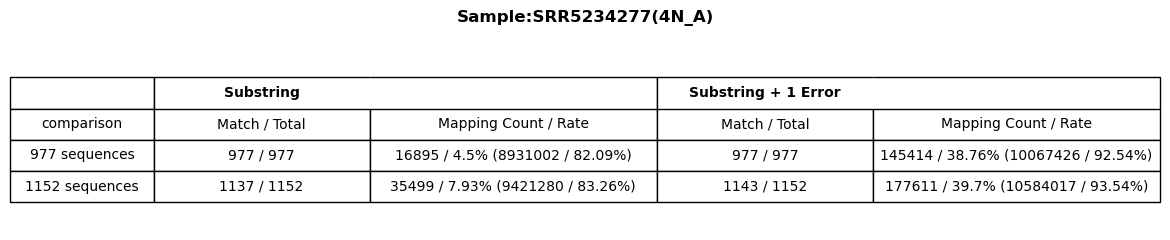

In [8]:
import matplotlib.pyplot as plt


data = [
    ["977 / 977", "16895 / 4.5% (8931002 / 82.09%)", "977 / 977", "145414 / 38.76% (10067426 / 92.54%)"],
    ["1137 / 1152", "35499 / 7.93% (9421280 / 83.26%)", "1143 / 1152", "177611 / 39.7% (10584017 / 93.54%)"]
]


row_labels = ["977 sequences", "1152 sequences"]


header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]


header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]


fig, ax = plt.subplots(figsize=(14, 2.5))
ax.axis('off')
plt.title("Sample:SRR5234277(4N_A)", fontsize=12, weight='bold', pad=20)


table = ax.table(
    cellText=table_data,
    cellLoc='center',
    loc='center',
    colWidths=[0.2, 0.3, 0.4, 0.3, 0.4]
)


table.scale(1, 2)
table.auto_set_font_size(False)
table.set_fontsize(10)


for col in range(1, 5):
    table[(0, col)].set_text_props(weight='bold')

for (row, col) in table.get_celld():
    cell = table[(row, col)]
    if row == 0 and col in [2, 4]:
        cell.visible_edges = 'RT'  
    elif row == 0 and col in [1, 3]:
        cell.visible_edges = 'LT' 

# Optional: save as image
# plt.savefig("substring_table_grouped.png", dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# Data rows
data = [
    ["977 / 977", "16895 / 4.5% (8931002 / 82.09%)", "977 / 977", "145414 / 38.76% (10067426 / 92.54%)"],
    ["1137 / 1152", "35499 / 7.93% (9421280 / 83.26%)", "1143 / 1152", "177611 / 39.7% (10584017 / 93.54%)"]
]

# Row labels
row_labels = ["977 sequences", "1152 sequences"]

# First header row (group headers)
header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]

# Second header row (column titles under each group)
header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

# Combine full table: 2 header rows + data rows
table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]
# # Combine rows
# table_data = [header_1, header_2] + data_rows

# Convert to DataFrame (keep headers as normal rows)
df = pd.DataFrame(table_data)

# Save to Excel
df.to_excel("Supplementary_Table_5_benchmark.xlsx", index=False, header=False)
# # Create figure
# fig, ax = plt.subplots(figsize=(14, 2.5))
# ax.axis('off')
# plt.title("Sample:SRR5234277(4N_A)", fontsize=12, weight='bold', pad=20)

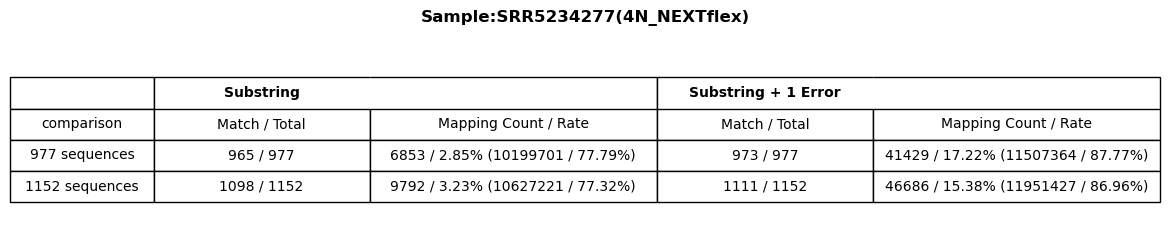

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
# Data rows
data = [
    ["965 / 977", "6853 / 2.85% (10199701 / 77.79%)", "973 / 977", "41429 / 17.22% (11507364 / 87.77%)"],
    ["1098 / 1152", "9792 / 3.23% (10627221 / 77.32%)", "1111 / 1152", "46686 / 15.38% (11951427 / 86.96%)"]
]

# Row labels
row_labels = ["977 sequences", "1152 sequences"]

# First header row (group headers)
header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]

# Second header row (column titles under each group)
header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

# Combine full table: 2 header rows + data rows
table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]

# # Create figure
# fig, ax = plt.subplots(figsize=(14, 2.5))
# ax.axis('off')
# plt.title("Sample:SRR5234277(4N_NEXTflex)", fontsize=12, weight='bold', pad=20)

#Add table to the figure
table = ax.table(
    cellText=table_data,
    cellLoc='center',
    loc='center',
    colWidths=[0.2, 0.3, 0.4, 0.3, 0.4]
)

# Style: increase size
table.scale(1, 2)
table.auto_set_font_size(False)
table.set_fontsize(10)

# Bold the group headers in first row
for col in range(1, 5):
    table[(0, col)].set_text_props(weight='bold')

# Merge effect: hide left/right borders between grouped columns in row 0
for (row, col) in table.get_celld():
    cell = table[(row, col)]
    if row == 0 and col in [2, 4]:
        cell.visible_edges = 'RT'  # right and top only
    elif row == 0 and col in [1, 3]:
        cell.visible_edges = 'LT'  # left and top only

# Optional: save as image
# plt.savefig("substring_table_grouped.png", dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

In [3]:
import matplotlib.pyplot as plt

# Data rows
data = [
    ["965 / 977", "6853 / 2.85% (10199701 / 77.79%)", "973 / 977", "41429 / 17.22% (11507364 / 87.77%)"],
    ["1098 / 1152", "9792 / 3.23% (10627221 / 77.32%)", "1111 / 1152", "46686 / 15.38% (11951427 / 86.96%)"]
]

# Row labels
row_labels = ["977 sequences", "1152 sequences"]

# First header row (group headers)
header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]

# Second header row (column titles under each group)
header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

# Combine full table: 2 header rows + data rows
table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]
# Convert to DataFrame (keep headers as normal rows)
df = pd.DataFrame(table_data)

# Save to Excel
df.to_excel("table5_2.xlsx", index=False, header=False)
# # Create figure
# fig, ax = plt.subplots(figsize=(14, 2.5))
# ax.axis('off')
# plt.title("Sample:SRR5234277(4N_NEXTflex)", fontsize=12, weight='bold', pad=20)

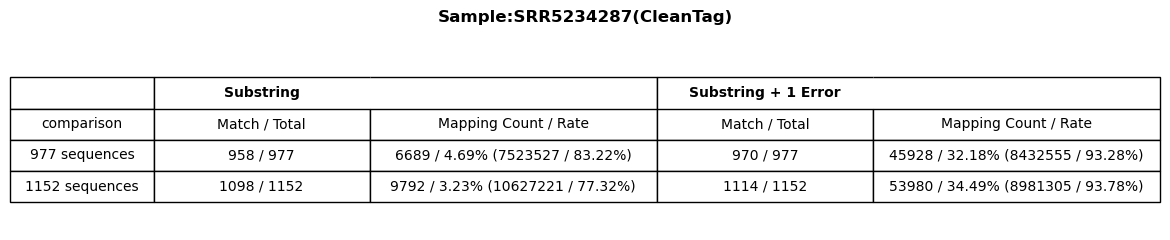

In [10]:
import matplotlib.pyplot as plt

# Data rows
data = [
    ["958 / 977", "6689 / 4.69% (7523527 / 83.22%)", "970 / 977", "45928 / 32.18% (8432555 / 93.28%)"],
    ["1098 / 1152", "9792 / 3.23% (10627221 / 77.32%)", "1114 / 1152", "53980 / 34.49% (8981305 / 93.78%)"]
]

# Row labels
row_labels = ["977 sequences", "1152 sequences"]

# First header row (group headers)
header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]

# Second header row (column titles under each group)
header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

# Combine full table: 2 header rows + data rows
table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]

# Create figure
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.axis('off')
plt.title("Sample:SRR5234287(CleanTag)", fontsize=12, weight='bold', pad=20)

#Add table to the figure
table = ax.table(
    cellText=table_data,
    cellLoc='center',
    loc='center',
    colWidths=[0.2, 0.3, 0.4, 0.3, 0.4]
)

# Style: increase size
table.scale(1, 2)
table.auto_set_font_size(False)
table.set_fontsize(10)

# Bold the group headers in first row
for col in range(1, 5):
    table[(0, col)].set_text_props(weight='bold')

# Merge effect: hide left/right borders between grouped columns in row 0
for (row, col) in table.get_celld():
    cell = table[(row, col)]
    if row == 0 and col in [2, 4]:
        cell.visible_edges = 'RT'  # right and top only
    elif row == 0 and col in [1, 3]:
        cell.visible_edges = 'LT'  # left and top only

# Optional: save as image
# plt.savefig("substring_table_grouped.png", dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

In [4]:
import matplotlib.pyplot as plt

# Data rows
data = [
    ["958 / 977", "6689 / 4.69% (7523527 / 83.22%)", "970 / 977", "45928 / 32.18% (8432555 / 93.28%)"],
    ["1098 / 1152", "9792 / 3.23% (10627221 / 77.32%)", "1114 / 1152", "53980 / 34.49% (8981305 / 93.78%)"]
]

# Row labels
row_labels = ["977 sequences", "1152 sequences"]

# First header row (group headers)
header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]

# Second header row (column titles under each group)
header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

# Combine full table: 2 header rows + data rows
table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]
# Convert to DataFrame (keep headers as normal rows)
df = pd.DataFrame(table_data)

# Save to Excel
df.to_excel("table5_3.xlsx", index=False, header=False)
# # Create figure
# fig, ax = plt.subplots(figsize=(14, 2.5))
# ax.axis('off')
# plt.title("Sample:SRR5234287(CleanTag)", fontsize=12, weight='bold', pad=20)

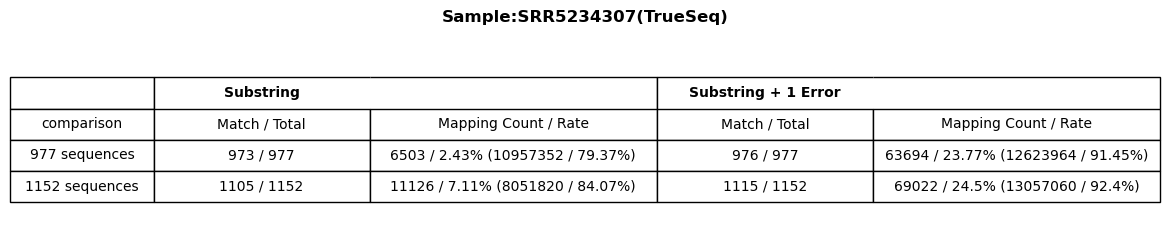

In [11]:
import matplotlib.pyplot as plt

# Data rows
data = [
    ["973 / 977", "6503 / 2.43% (10957352 / 79.37%)", "976 / 977", "63694 / 23.77% (12623964 / 91.45%)"],
    ["1105 / 1152", "11126 / 7.11% (8051820 / 84.07%)", "1115 / 1152", "69022 / 24.5% (13057060 / 92.4%)"]
]
# Row labels
row_labels = ["977 sequences", "1152 sequences"]

# First header row (group headers)
header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]

# Second header row (column titles under each group)
header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

# Combine full table: 2 header rows + data rows
table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]

# Create figure
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.axis('off')
plt.title("Sample:SRR5234307(TrueSeq)", fontsize=12, weight='bold', pad=20)

#Add table to the figure
table = ax.table(
    cellText=table_data,
    cellLoc='center',
    loc='center',
    colWidths=[0.2, 0.3, 0.4, 0.3, 0.4]
)

# Style: increase size
table.scale(1, 2)
table.auto_set_font_size(False)
table.set_fontsize(10)

# Bold the group headers in first row
for col in range(1, 5):
    table[(0, col)].set_text_props(weight='bold')

# Merge effect: hide left/right borders between grouped columns in row 0
for (row, col) in table.get_celld():
    cell = table[(row, col)]
    if row == 0 and col in [2, 4]:
        cell.visible_edges = 'RT'  # right and top only
    elif row == 0 and col in [1, 3]:
        cell.visible_edges = 'LT'  # left and top only

# Optional: save as image
# plt.savefig("substring_table_grouped.png", dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

In [5]:
import matplotlib.pyplot as plt

# Data rows
data = [
    ["973 / 977", "6503 / 2.43% (10957352 / 79.37%)", "976 / 977", "63694 / 23.77% (12623964 / 91.45%)"],
    ["1105 / 1152", "11126 / 7.11% (8051820 / 84.07%)", "1115 / 1152", "69022 / 24.5% (13057060 / 92.4%)"]
]
# Row labels
row_labels = ["977 sequences", "1152 sequences"]

# First header row (group headers)
header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]

# Second header row (column titles under each group)
header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

# Combine full table: 2 header rows + data rows
table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]
# Convert to DataFrame (keep headers as normal rows)
df = pd.DataFrame(table_data)

# Save to Excel
df.to_excel("table5_4.xlsx", index=False, header=False)
# # Create figure
# fig, ax = plt.subplots(figsize=(14, 2.5))
# ax.axis('off')
# plt.title("Sample:", fontsize=12, weight='bold', pad=20)

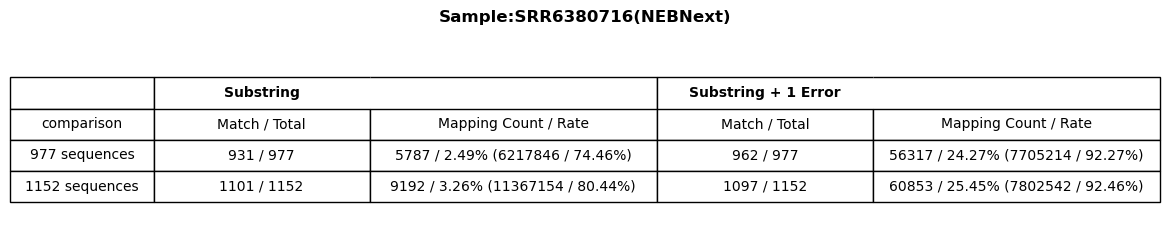

In [12]:
import matplotlib.pyplot as plt

# Data rows
data = [
    ["931 / 977", "5787 / 2.49% (6217846 / 74.46%)", "962 / 977", "56317 / 24.27% (7705214 / 92.27%)"],
    ["1101 / 1152", "9192 / 3.26% (11367154 / 80.44%)", "1097 / 1152", "60853 / 25.45% (7802542 / 92.46%)"]
]

# Row labels
row_labels = ["977 sequences", "1152 sequences"]

# First header row (group headers)
header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]

# Second header row (column titles under each group)
header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

# Combine full table: 2 header rows + data rows
table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]

# Create figure
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.axis('off')
plt.title("Sample:SRR6380716(NEBNext)", fontsize=12, weight='bold', pad=20)

#Add table to the figure
table = ax.table(
    cellText=table_data,
    cellLoc='center',
    loc='center',
    colWidths=[0.2, 0.3, 0.4, 0.3, 0.4]
)

# Style: increase size
table.scale(1, 2)
table.auto_set_font_size(False)
table.set_fontsize(10)

# Bold the group headers in first row
for col in range(1, 5):
    table[(0, col)].set_text_props(weight='bold')

# Merge effect: hide left/right borders between grouped columns in row 0
for (row, col) in table.get_celld():
    cell = table[(row, col)]
    if row == 0 and col in [2, 4]:
        cell.visible_edges = 'RT'  # right and top only
    elif row == 0 and col in [1, 3]:
        cell.visible_edges = 'LT'  # left and top only

# Optional: save as image
# plt.savefig("substring_table_grouped.png", dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt

# Data rows
data = [
    ["931 / 977", "5787 / 2.49% (6217846 / 74.46%)", "962 / 977", "56317 / 24.27% (7705214 / 92.27%)"],
    ["1101 / 1152", "9192 / 3.26% (11367154 / 80.44%)", "1097 / 1152", "60853 / 25.45% (7802542 / 92.46%)"]
]

# Row labels
row_labels = ["977 sequences", "1152 sequences"]

# First header row (group headers)
header_row_1 = ["", "Substring", "", "Substring + 1 Error", ""]

# Second header row (column titles under each group)
header_row_2 = ["comparison", "Match / Total", "Mapping Count / Rate", "Match / Total", "Mapping Count / Rate"]

# Combine full table: 2 header rows + data rows
table_data = [header_row_1, header_row_2] + [
    [row_labels[i]] + data[i] for i in range(len(data))
]
# Convert to DataFrame (keep headers as normal rows)
df = pd.DataFrame(table_data)

# Save to Excel
df.to_excel("table5_5.xlsx", index=False, header=False)
# # Create figure
# fig, ax = plt.subplots(figsize=(14, 2.5))
# ax.axis('off')
# plt.title("Sample:SRR6380716(NEBNext)", fontsize=12, weight='bold', pad=20)